<a href="https://colab.research.google.com/github/HChathurika/2ndY_2ndSem_2ndPe_Project_Assignment/blob/main/Week-01/Neural_Network_Week1_Activity4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



#Activity 4: The Concrete Strength MLP Challenge

##1.Meet the concrete dataset

In [1]:

!pip install numpy pandas matplotlib scikit-learn keras tensorflow


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import Sequential, Input
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(32)

concrete_data = pd.read_csv(
    "https://raw.githubusercontent.com/AI-Learning-Repo/resources/refs/heads/main/datasets/concrete.csv"
)


In [3]:

print(concrete_data.head())
print("Shape:", concrete_data.shape)
print("Columns:", concrete_data.columns.tolist())
print("Missing values:\n", concrete_data.isna().sum())


   Cement  BlastFurnaceSlag  FlyAsh  Water  Superplasticizer  CoarseAggregate  \
0   540.0               0.0     0.0  162.0               2.5           1040.0   
1   540.0               0.0     0.0  162.0               2.5           1055.0   
2   332.5             142.5     0.0  228.0               0.0            932.0   
3   332.5             142.5     0.0  228.0               0.0            932.0   
4   198.6             132.4     0.0  192.0               0.0            978.4   

   FineAggregate  Age  CompressiveStrength  
0          676.0   28                79.99  
1          676.0   28                61.89  
2          594.0  270                40.27  
3          594.0  365                41.05  
4          825.5  360                44.30  
Shape: (1030, 9)
Columns: ['Cement', 'BlastFurnaceSlag', 'FlyAsh', 'Water', 'Superplasticizer', 'CoarseAggregate', 'FineAggregate', 'Age', 'CompressiveStrength']
Missing values:
 Cement                 0
BlastFurnaceSlag       0
FlyAsh        




**Q1. Display the first five rows and column names.**

The first five rows are displayed using `concrete_data.head()`, and the column names are displayed using `concrete_data.columns.tolist()`.

**Q2. How many rows and columns are in the dataset?**

The dataset contains 1,030 rows and 9 columns.

**Q3. Are there missing values?**

No. The dataset has no missing values reported by `.isna().sum()`.

**Q4. What is the target and how many input features are there?**

The target is `CompressiveStrength`, and there are 8 input features.

**Q5. Is this regression or classification?**

This is regression because the model predicts a continuous numerical value representing concrete compressive strength in MPa.


##2.Separate input features and target

In [4]:

concrete_features = concrete_data.drop(columns=["CompressiveStrength"])
concrete_target = concrete_data["CompressiveStrength"]

print("Feature shape:", concrete_features.shape)
print("Target shape:", concrete_target.shape)


Feature shape: (1030, 8)
Target shape: (1030,)





What would go wrong if `CompressiveStrength` were also included among the features?**

Including `CompressiveStrength` in the input features would cause target leakage. The model would receive the answer it is supposed to predict, making the evaluation results misleading.


##3.Split into training, validation, and test sets

In [5]:

X_train_val, X_test, y_train_val, y_test = train_test_split(
    concrete_features, concrete_target,
    test_size=0.20, random_state=32
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.20, random_state=32
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training: (659, 8)
Validation: (165, 8)
Test: (206, 8)



##3. Questions and Answers

**Q1. Why do we keep a separate validation set?**

The validation set helps us compare different models and select the best configuration without using the final test data.

**Q2. Why should we not repeatedly evaluate architectures on the test set?**

Repeatedly using the test set to choose models can lead to overfitting to the test data and produce an overly optimistic evaluation.


##4.Standardize the input features

In [6]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Training feature means:", np.round(X_train_scaled.mean(axis=0), 6))


Scaled training shape: (659, 8)
Training feature means: [-0.  0. -0. -0. -0. -0. -0. -0.]




**Q1. Why is `fit_transform()` applied only to training data?**

It calculates scaling statistics from the training data and applies them, preventing information leakage from validation and test data.

**Q2. What is the approximate mean of each scaled training feature?**

Each standardized training feature has a mean approximately equal to zero.

**Q3. Why should we not fit a new scaler on validation and test data?**

The validation and test sets must use the same scaling parameters learned from the training data to maintain consistency and prevent data leakage.


## 5. Build the baseline MLP

In [7]:

concrete_model = Sequential(name="Concrete_MLP")
concrete_model.add(Input(shape=(X_train_scaled.shape[1],)))
concrete_model.add(Dense(128, activation="relu"))
concrete_model.add(Dense(64, activation="relu"))
concrete_model.add(Dense(1))  # Linear output (default)
concrete_model.summary()


Model: "Concrete_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,473 (37.00 KB)

 Trainable params: 9,473 (37.00 KB)

 Non-trainable params: 0 (0.00 B)




**Q1. Why is there one output neuron?**

One output neuron is used because the model predicts one continuous value: concrete compressive strength.

**Q2. Why is the output linear instead of sigmoid?**

A linear activation allows numerical predictions outside the 0–1 range. Sigmoid is used for binary classification, while linear output is appropriate for regression.

**Q3. Calculate the total number of trainable weights and biases.**

| Layer | Calculation | Parameters |
|---|---|---|
| Input → Hidden 1 | (8 × 128) + 128 | 1,152 |
| Hidden 1 → Hidden 2 | (128 × 64) + 64 | 8,256 |
| Hidden 2 → Output | (64 × 1) + 1 | 65 |
| **Total** | | **9,473** |


##6. Compile the MLP

In [8]:

concrete_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)




**Q. Why is classification accuracy inappropriate here? What are the units of MSE and MAE?**

Classification accuracy is unsuitable because concrete strength is a continuous numerical value rather than a class label. MAE measures average absolute prediction error in MPa, while MSE measures average squared error in MPa².


##7.Train the baseline model

In [10]:

history_concrete = concrete_model.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val_scaled, y_val),
    verbose=0
)
print("Final training MAE:", round(history_concrete.history["mae"][-1], 2))
print("Final validation MAE:", round(history_concrete.history["val_mae"][-1], 2))


Final training MAE: 4.22
Final validation MAE: 5.41





**Q1. What does an epoch mean?**

An epoch is one complete pass through the training dataset.

**Q2. What do training MAE and validation MAE measure?**

Training MAE measures the average absolute prediction error on training samples. Validation MAE measures the same error on held-out validation samples.

**Q3. Does a lower training loss guarantee a lower validation loss?**

No. Training loss can decrease while validation loss increases, which may indicate overfitting.


## 8. Visualize training and validation results

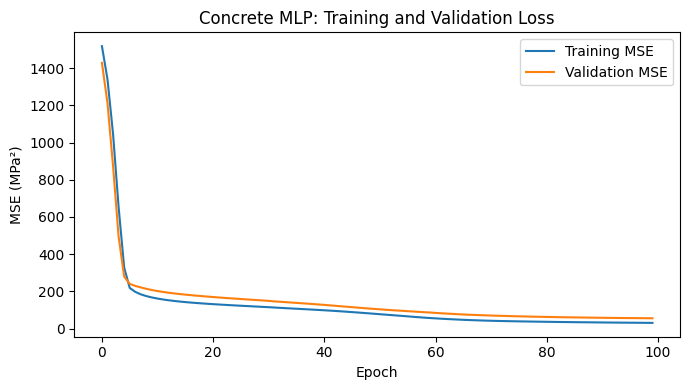

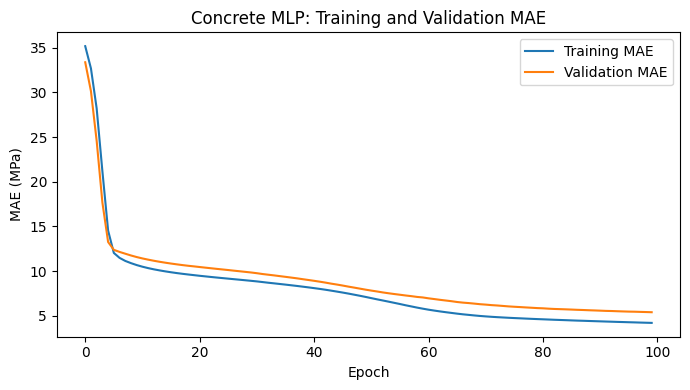

In [11]:

plt.figure(figsize=(7, 4))
plt.plot(history_concrete.history["loss"], label="Training MSE")
plt.plot(history_concrete.history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE (MPa²)")
plt.title("Concrete MLP: Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history_concrete.history["mae"], label="Training MAE")
plt.plot(history_concrete.history["val_mae"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (MPa)")
plt.title("Concrete MLP: Training and Validation MAE")
plt.legend()
plt.tight_layout()
plt.show()


##8.Visualize training and validation results

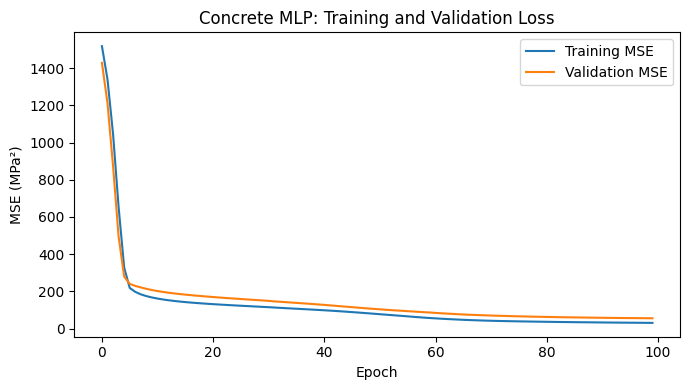

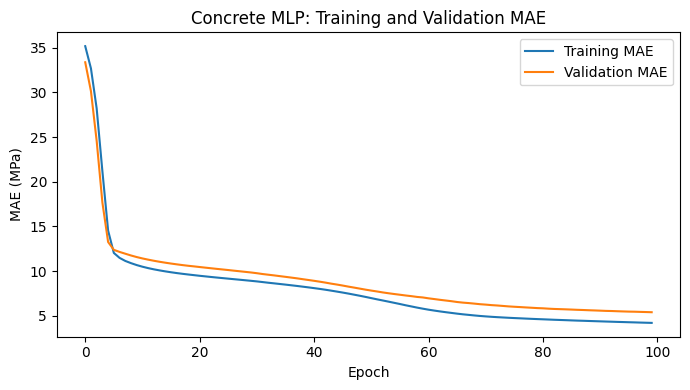

In [12]:

plt.figure(figsize=(7, 4))
plt.plot(history_concrete.history["loss"], label="Training MSE")
plt.plot(history_concrete.history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE (MPa²)")
plt.title("Concrete MLP: Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history_concrete.history["mae"], label="Training MAE")
plt.plot(history_concrete.history["val_mae"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (MPa)")
plt.title("Concrete MLP: Training and Validation MAE")
plt.legend()
plt.tight_layout()
plt.show()




**Q1. Does validation loss follow the same pattern as training loss?**

Validation loss may follow a similar decreasing trend, but it can fluctuate because it measures performance on separate data. The exact pattern should be checked against the graphs.

**Q2. What might it mean if training loss decreases while validation loss increases?**

This may indicate overfitting. The model is improving on training data but performing worse on unseen validation data.

**Q3. Why does an MAE plot have more intuitive units than an MSE plot?**

MAE is measured directly in MPa, the same unit as concrete strength. MSE is measured in MPa², making it less intuitive to interpret.


##9. Experiment and select a model before testing

In [13]:

keras.utils.set_random_seed(32)

candidate_model = Sequential(name="Concrete_Candidate")
candidate_model.add(Input(shape=(X_train_scaled.shape[1],)))
candidate_model.add(Dense(64, activation="relu"))
candidate_model.add(Dense(32, activation="relu"))
candidate_model.add(Dense(1))

candidate_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

candidate_history = candidate_model.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val_scaled, y_val),
    verbose=0
)

baseline_val_mae = history_concrete.history["val_mae"][-1]
candidate_val_mae = candidate_history.history["val_mae"][-1]

print(f"Baseline final validation MAE: {baseline_val_mae:.2f} MPa")
print(f"Candidate final validation MAE: {candidate_val_mae:.2f} MPa")

if candidate_val_mae < baseline_val_mae:
    final_model = candidate_model
    print("Selected candidate using validation MAE.")
else:
    final_model = concrete_model
    print("Selected baseline using validation MAE.")


Baseline final validation MAE: 5.41 MPa
Candidate final validation MAE: 6.21 MPa
Selected baseline using validation MAE.





**Prediction before running:**

Reducing the number of hidden neurons decreases model complexity. It may reduce overfitting, but it may also reduce the model's ability to learn complex relationships.

| Model | Architecture and epochs | Final validation MAE (MPa) | Observation |
|---|---|---|---|
| Baseline | 128 → 64 → 1; 100 epochs | | Original model |
| Candidate 1 | 64 → 32 → 1; 100 epochs | | Smaller model |


##10.Final evaluation on the test set

In [14]:

test_mse, test_mae = final_model.evaluate(
    X_test_scaled, y_test, verbose=0
)

print(f"Final test MSE: {test_mse:.2f} MPa²")
print(f"Final test MAE: {test_mae:.2f} MPa")


Final test MSE: 40.92 MPa²
Final test MAE: 4.69 MPa




**Q. If test MAE is 5 MPa, does that mean every individual prediction is within 5 MPa of its target?**

No. An MAE of 5 MPa means that the average absolute prediction error is 5 MPa. Some individual errors may be smaller and others larger.


## 11.Inspect predictions and individual errors

In [15]:

predictions = final_model.predict(X_test_scaled, verbose=0).flatten()

results = pd.DataFrame({
    "Actual (MPa)": y_test.to_numpy(),
    "Predicted (MPa)": predictions
})

results["Absolute error (MPa)"] = (
    results["Actual (MPa)"] - results["Predicted (MPa)"]
).abs()

print(results.head(10).round(2))

shown = results.head(10)

print("Smallest of displayed errors:\n",
      shown.loc[shown["Absolute error (MPa)"].idxmin()])

print("Largest of displayed errors:\n",
      shown.loc[shown["Absolute error (MPa)"].idxmax()])


   Actual (MPa)  Predicted (MPa)  Absolute error (MPa)
0         18.28        30.500000                 12.22
1         31.02        37.290001                  6.27
2         12.84        14.170000                  1.33
3         53.90        39.070000                 14.83
4         39.70        34.980000                  4.72
5         31.12        33.869999                  2.75
6         61.92        62.060001                  0.14
7         56.81        56.790001                  0.02
8         40.87        40.799999                  0.07
9         43.50        41.680000                  1.82
Smallest of displayed errors:
 Actual (MPa)            56.81000
Predicted (MPa)         56.78717
Absolute error (MPa)     0.02283
Name: 7, dtype: float64
Largest of displayed errors:
 Actual (MPa)            53.900000
Predicted (MPa)         39.067101
Absolute error (MPa)    14.832899
Name: 3, dtype: float64





**Q1. Does the model predict all mixtures equally well?**

No. Prediction errors differ between concrete mixtures. Some predictions are closer to the actual values than others.

**Q2. What measured or unmeasured factors might contribute to errors?**

Errors may result from differences in ingredient proportions, curing age, measurement variation, and environmental or material conditions not included in the dataset.

**Q3. Why should this small educational model not replace laboratory strength testing?**

The model only estimates strength based on historical data. Its predictions may contain errors, so laboratory testing is still necessary for accurate and safety-critical engineering decisions.


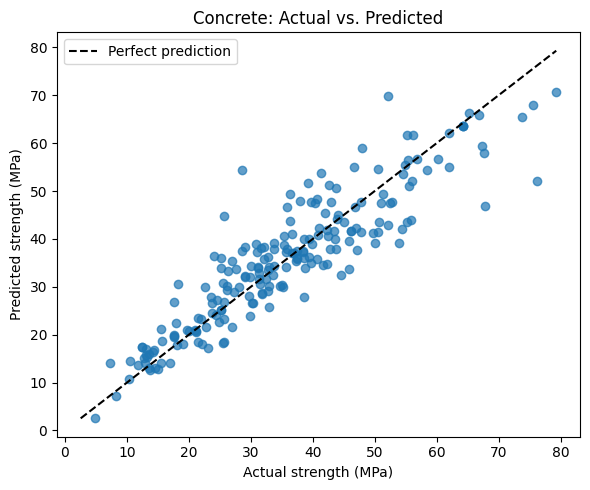

In [16]:

plt.figure(figsize=(6, 5))
plt.scatter(results["Actual (MPa)"], results["Predicted (MPa)"], alpha=0.7)

limits = [
    min(results["Actual (MPa)"].min(), results["Predicted (MPa)"].min()),
    max(results["Actual (MPa)"].max(), results["Predicted (MPa)"].max())
]

plt.plot(limits, limits, "k--", label="Perfect prediction")
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Concrete: Actual vs. Predicted")
plt.legend()
plt.tight_layout()
plt.show()



## Conclusion and Reflection

| Model | Task | Target | Output activation | Evaluation |
|---|---|---|---|---|
| XOR | Binary classification | 0 or 1 | Sigmoid | Binary cross-entropy and accuracy |
| Cereal | Regression | Numerical cereal rating | Linear | MSE and MAE in rating points |
| Concrete | Regression | Compressive strength in MPa | Linear | MSE and MAE in MPa |

**Reflection:**

The XOR model performs binary classification, while the cereal and concrete models perform regression. XOR uses a sigmoid output to predict binary classes. The regression models use linear outputs to predict continuous numerical values. All three models use Keras and hidden layers, but they use different loss functions and evaluation metrics depending on the prediction task.
